# Practice with matrices

The two examples here are common things that can go wrong when you create a matrix "incorrectly". Note that the matrix itself is actually correct in terms of the syntax and the math, it's just that it isn't what you (usually) want for moving objects around.

See also Lecture slides https://docs.google.com/presentation/d/12p3VOVT5yL14-1z5T20hTscpVC0hsxjtvMLHmQLFITk/edit?usp=sharing

In [1]:
import numpy as np
from matplotlib import pyplot as plt

# All of the matrix routines are in here - we can import the Python (.py) file just like the imports above
#  All of the functions in there will be accessed as mr.
import matrix_routines as mr

# The same plot functions as were used in the tutorial
from matrix_routines import plot_pts, plot_axes_and_big_box, plot_transformed_axes

In [9]:
## The points from the tutorial - plus some other ones you can practice with
# It's easier to start with a numpy array that has ones in it to make the points because you'll need ones in the 3rd row
n_points = 3
pts_triangle = np.ones((3, n_points))
# Make a right-sided triangle with the center of the origin in the middle
pts_triangle[0:2, 0] = [-2.0, 1.25]  # Upper left corner
pts_triangle[0:2, 1] = [2.0, -0.5]   # Pointy bit at the right
pts_triangle[0:2, 2] = [-2.0, -0.5]   # 90 degree angle part

# Points on a circle
n_pts_circle = 32
# The angles
thetas = np.linspace(0, np.pi * 2, n_pts_circle)
pts_circle = np.ones(shape=(3, n_pts_circle))
pts_circle[0, :] = np.cos(thetas)
pts_circle[1, :] = np.sin(thetas)
print(pts_triangle)

[[-2.    2.   -2.  ]
 [ 1.25 -0.5  -0.5 ]
 [ 1.    1.    1.  ]]


### Example: Uncentered geometry

A common (and subtle) problem is that (most of the time) the assumption is that the geometry is centered around the origin - otherwise, when you rotate the object it moves, too. Think of an object sitting on the edge of a spinning platter - as the platter spins, the object both rotates and translates.

For the first example, the matrix transform stays the same but the object is in a different place

[[0.   4.   0.  ]
 [1.75 0.   0.  ]
 [1.   1.   1.  ]]
[[ 1.52532199  1.50485193  1.4442798   1.34608543  1.21428891  1.054286
   0.87262724  0.67674977  0.47467282  0.27466946  0.08492784 -0.08678399
  -0.23343613 -0.34902463 -0.42881727 -0.46954733 -0.46954733 -0.42881727
  -0.34902463 -0.23343613 -0.08678399  0.08492784  0.27466946  0.47467282
   0.67674977  0.87262724  1.054286    1.21428891  1.34608543  1.4442798
   1.50485193  1.52532199]
 [ 0.52532199  0.72662051  0.91967784  1.0965902   1.25011478  1.37396625
   1.46307412  1.51379031  1.5240385   1.49339911  1.42312653  1.31609773
   1.17669447  1.01062395  0.82468511  0.62649031  0.42415367  0.22595887
   0.04002003 -0.12605049 -0.26545375 -0.37248255 -0.44275513 -0.47339452
  -0.46314634 -0.41243014 -0.32332227 -0.1994708  -0.04594623  0.13096613
   0.32402347  0.52532199]
 [ 1.          1.          1.          1.          1.          1.
   1.          1.          1.          1.          1.          1.
   1.          1.     

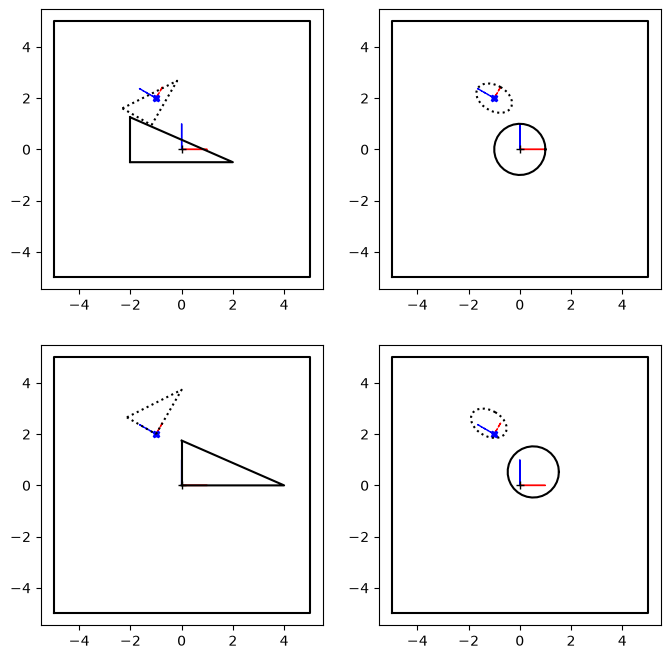

In [19]:
fig, axs = plt.subplots(2, 2, figsize=(8, 8))

# First plot is the "normal" one

# GUIDE: Change the two mat_trans to move the lower left point of the shape to the origin
mat_trans_triangle = mr.make_translation_matrix(2, 0.5)
mat_trans_circle = mr.make_translation_matrix(np.cos(45), np.cos(45))  # Move -1, -1 to 0,0
pts_triangle_lower_left_origin = mat_trans_triangle @ pts_triangle   # Put the matrix before pts_triangle
print(pts_triangle_lower_left_origin)
pts_circle_lower_left_origin = mat_trans_circle @ pts_circle  # Put a matrix before pts_circle
print(pts_circle_lower_left_origin)


# Make a scale, rotation, translation matrix
mat_scl_rot_trans = mr.make_translation_matrix(-1, 2) @ \
                    mr.make_rotation_matrix(np.pi / 3.0) @ \
                    mr.make_scale_matrix(0.5, 0.75)   # pts go here


# Plot the big box and axes for all plots
for indx in range(0, 4):
    plot_axes_and_big_box(axs[indx // 2, indx % 2])


first_row = (pts_triangle, pts_circle)
second_row = (pts_triangle_lower_left_origin, pts_circle_lower_left_origin)
for ir, row in enumerate((first_row, second_row)):
    for ic, pts in enumerate(row):
        # Draw the original points
        plot_pts(axs[ir, ic], pts)

        # This is the transformation for all four cases
        plot_transformed_axes(axs[ir, ic], mat_scl_rot_trans)

        # Plot the transformed points
        pts_transformed = mat_scl_rot_trans @ pts
        plot_pts(axs[ir, ic], pts_transformed, fmt=":k")


# Answers

Note: Just putting the lines that need to change here


In [4]:
mat_trans_triangle = mr.make_translation_matrix(-pts_triangle[0, -1], -pts_triangle[1, -1]) # Move the lower left corner (the last point) to (0,0)
mat_trans_circle = mr.make_translation_matrix(0, 0)

pts_triangle_lower_left_origin = mat_trans_triangle @ pts_triangle   # Put the matrix before pts_triangle
pts_circle_lower_left_origin = mat_trans_circle @ pts_circle  # Put a matrix before pts_circle
